# 03 - Segmentation 2D des coupes HDF5

Le dataset disponible est en 2D. Les quatre modalités sont utilisées comme canaux d'entrée et les trois canaux du masque sont fusionnés en cible binaire.

In [6]:
from pathlib import Path
import sys
import h5py
import numpy as np
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_ROOT = REPO_ROOT / "data/raw/data"
sys.path.insert(0, str(REPO_ROOT / "src"))
from brain_mri_fem.segmentation import UNet2D, dice, iou
from brain_mri_fem.utils import seed_everything

seed_everything(42)
files = sorted(DATA_ROOT.glob("*.h5"))
if not files:
    raise FileNotFoundError(f"Aucun fichier HDF5 dans {DATA_ROOT}")
print(f"Coupes disponibles: {len(files)}")

Coupes disponibles: 57195


In [7]:
def normalize(image: np.ndarray) -> np.ndarray:
    image = image.astype(np.float32)
    output = np.zeros_like(image)
    for channel in range(image.shape[-1]):
        values = image[:, :, channel]
        active = values != 0
        if active.any():
            output[:, :, channel][active] = (values[active] - values[active].mean()) / max(values[active].std(), 1e-6)
    return output

class H5Slices(Dataset):
    def __init__(self, paths):
        self.paths = paths
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, index):
        with h5py.File(self.paths[index], "r") as handle:
            image = normalize(handle["image"][:])
            target = handle["mask"][:].any(axis=-1).astype(np.int64)
        return torch.from_numpy(image.transpose(2, 0, 1)), torch.from_numpy(target)

train_paths = files[: min(16, len(files))]
loader = DataLoader(H5Slices(train_paths), batch_size=2, shuffle=True, num_workers=0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = UNet2D(in_channels=4, out_channels=2, channels=(8, 16, 32)).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()
print("Device:", device, "Coupes d'entraînement:", len(train_paths))

Device: cpu Coupes d'entraînement: 16


In [8]:
model.train()
losses = []
for images, targets in loader:
    images, targets = images.to(device), targets.to(device)
    optimizer.zero_grad()
    loss = criterion(model(images), targets)
    loss.backward()
    optimizer.step()
    losses.append(float(loss.detach()))
print("Loss moyenne après une passe:", float(np.mean(losses)))

Loss moyenne après une passe: 0.6607161536812782


Dice: 2.3001196062189946e-13 IoU: 2.3001196062189946e-13


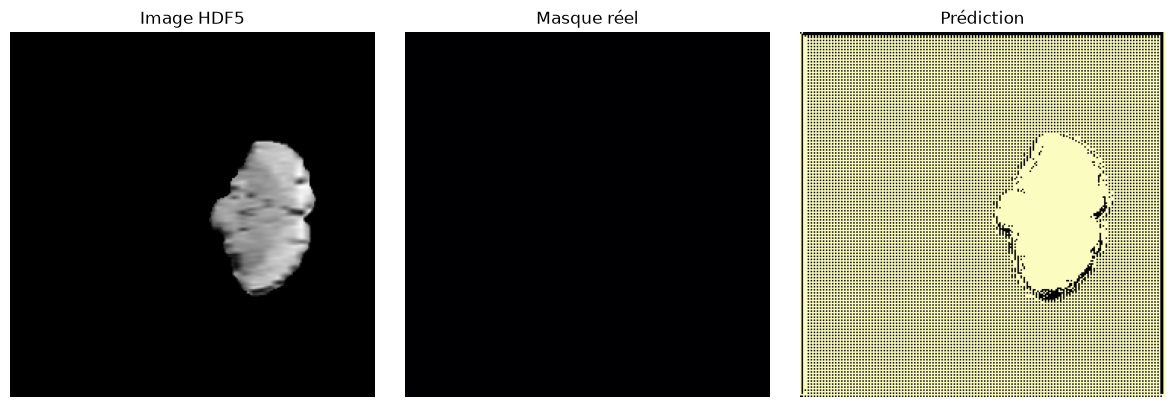

In [9]:
model.eval()
image, target = H5Slices([files[len(files) // 2]])[0]
with torch.no_grad():
    prediction = model(image.unsqueeze(0).to(device)).argmax(dim=1).cpu().numpy()[0]
print("Dice:", dice(prediction, target.numpy()), "IoU:", iou(prediction, target.numpy()))
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(image[0], cmap="gray"); axes[0].set_title("Image HDF5")
axes[1].imshow(target, cmap="magma"); axes[1].set_title("Masque réel")
axes[2].imshow(prediction, cmap="magma"); axes[2].set_title("Prédiction")
for axis in axes: axis.axis("off")
fig.tight_layout()
output = REPO_ROOT / "results/figures/segmentation"
output.mkdir(parents=True, exist_ok=True)
fig.savefig(output / "unet2d_h5_prediction.png", dpi=150)
plt.show()